DEA-AHP/GS - DEA GAUSSIAN AHP HYBRID METHOD


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr


In [2]:
df = pd.read_json("runs.jsonl", lines=True)

df

,run_id,example_id,timestamp,provider,model,model_version,prompt_text,system_text,context_text,temperature,...,status,http_status,error_type,retry_count,request_id,output_text,truncated,split,domain,difficulty
0,bb190b5d-13b0-47b6-b86f-12448e68b6ba,56dde1d966d3e219004dad8d,2025-08-20 23:10:48.625132799,openai,gpt-4.1-mini,gpt-4.1-mini-2025-04-14,Who upon arriving gave the original viking set...,Você é um modelo de QA conciso. Responda de fo...,"Before Rollo's arrival, its populations did no...",0,...,ok,NaN,NaN,0,chatcmpl-C6mF6m4VguvlHvaCIPpqDg4An9Oki,"Rollo, upon arriving, gave the original Viking...",False,test,generic-qa,NaN
1,5944e99a-ce6e-4890-8742-e09656c0606e,56ddde6b9a695914005b9628,2025-08-20 23:11:33.759105206,openai,gpt-4.1-mini,gpt-4.1-mini-2025-04-14,In what country is Normandy located?,Você é um modelo de QA conciso. Responda de fo...,The Normans (Norman: Nourmands; French: Norman...,0,...,ok,NaN,NaN,0,chatcmpl-C6mFpDcKpBID4tLrpc0t6uo7xbq0B,Normandy is located in France.,False,test,generic-qa,NaN
2,aeb06f1c-ece8-482e-8e61-c96cb6702ada,56ddde6b9a695914005b9629,2025-08-20 23:11:34.316069365,openai,gpt-4.1-mini,gpt-4.1-mini-2025-04-14,When were the Normans in Normandy?,Você é um modelo de QA conciso. Responda de fo...,The Normans (Norman: Nourmands; French: Norman...,0,...,ok,NaN,NaN,0,chatcmpl-C6mFqp8wVUghCaXc08FG2cUi92Fza,The Normans were in Normandy during the 10th a...,False,test,generic-qa,NaN
3,f0befde2-d427-4404-ba80-76ab44c6485f,56ddde6b9a695914005b962a,2025-08-20 23:11:34.935155630,openai,gpt-4.1-mini,gpt-4.1-mini-2025-04-14,From which countries did the Norse originate?,Você é um modelo de QA conciso. Responda de fo...,The Normans (Norman: Nourmands; French: Norman...,0,...,ok,NaN,NaN,0,chatcmpl-C6mFqhD8uWh8tyZ0FvFxxyLAuNLab,"The Norse originated from Denmark, Iceland, an...",False,test,generic-qa,NaN
4,e2585d3f-3f91-4d52-ae4b-36be2b90498c,56ddde6b9a695914005b962b,2025-08-20 23:11:35.457824469,openai,gpt-4.1-mini,gpt-4.1-mini-2025-04-14,Who was the Norse leader?,Você é um modelo de QA conciso. Responda de fo...,The Normans (Norman: Nourmands; French: Norman...,0,...,ok,NaN,NaN,0,chatcmpl-C6mFrshEiDgZ4gmddKOHLiZ8gvvMP,The Norse leader was Rollo.,False,test,generic-qa,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3996,906e7346-6a57-4b30-bee8-de9280e7a3da,be253c67-024a-4848-ac42-8ce578fa81b7,2025-08-21 01:35:25.733195782,gemini,gemini-1.5-flash,gemini-1.5-flash,when did the last spanish american veteran died,Você é um modelo de QA conciso. Responda de fo...,,0,...,ok,NaN,NaN,0,None,"The last known Spanish-American War veteran, ...",False,test,generic-qa,NaN
3997,dac8dd77-fbf6-4a40-8e4c-209ccd1be504,a2ee345a-f405-41af-a202-e8f3dddde949,2025-08-21 01:35:26.254196405,gemini,gemini-1.5-flash,gemini-1.5-flash,when did man u last win the fa cup,Você é um modelo de QA conciso. Responda de fo...,,0,...,ok,NaN,NaN,0,None,2016.,False,test,generic-qa,NaN
3998,03de96df-a73d-496a-b985-816ac12a4d2e,1bf04a21-6fe8-4f8a-87c6-2f90079618d8,2025-08-21 01:35:26.882445335,gemini,gemini-1.5-flash,gemini-1.5-flash,where does cooper's hawk wine come from,Você é um modelo de QA conciso. Responda de fo...,,0,...,ok,NaN,NaN,0,None,Cooper's Hawk Winery & Restaurants is based in...,False,test,generic-qa,NaN
3999,2c8f3b95-1b83-4990-a445-8491c6a2ab2c,61be56f4-a9e2-4408-ac8d-0d7ab85fd64f,2025-08-21 01:35:27.325576305,gemini,gemini-1.5-flash,gemini-1.5-flash,what port is associated with the dns service,Você é um modelo de QA conciso. Responda de fo...,,0,...,ok,NaN,NaN,0,None,Port 53.,False,test,generic-qa,NaN


EDA

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4001 entries, 0 to 4000
Data columns (total 34 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   run_id         4001 non-null   object        
 1   example_id     4001 non-null   object        
 2   timestamp      4001 non-null   datetime64[ns]
 3   provider       4001 non-null   object        
 4   model          4001 non-null   object        
 5   model_version  4001 non-null   object        
 6   prompt_text    4001 non-null   object        
 7   system_text    4001 non-null   object        
 8   context_text   4001 non-null   object        
 9   temperature    4001 non-null   int64         
 10  top_p          0 non-null      float64       
 11  max_tokens     4001 non-null   int64         
 12  seed           0 non-null      float64       
 13  stream         4001 non-null   bool          
 14  latency_ms     4001 non-null   float64       
 15  ttft_ms        0 non-

In [4]:
df.describe()

,timestamp,temperature,top_p,max_tokens,seed,latency_ms,ttft_ms,input_tokens,output_tokens,total_tokens,cost_input,cost_output,cost_total,http_status,error_type,retry_count,difficulty
count,4001,4001.0,0.0,4001.0,0.0,4001.000000,0.0,4001.000000,4001.000000,4001.000000,4001.000000,4.001000e+03,4001.000000,0.0,0.0,4001.0,0.0
mean,2025-08-21 00:28:19.400531456,0.0,NaN,256.0,NaN,753.485350,NaN,111.341415,17.070982,128.412397,0.000039,1.759948e-05,0.000056,NaN,NaN,0.0,NaN
min,2025-08-20 23:10:48.625132799,0.0,NaN,256.0,NaN,334.527400,NaN,33.000000,1.000000,36.000000,0.000002,6.000000e-07,0.000003,NaN,NaN,0.0,NaN
25%,2025-08-20 23:31:02.483329024,0.0,NaN,256.0,NaN,450.577300,NaN,36.000000,7.000000,46.000000,0.000003,2.400000e-06,0.000005,NaN,NaN,0.0,NaN
50%,2025-08-20 23:45:49.810486528,0.0,NaN,256.0,NaN,572.335400,NaN,74.000000,14.000000,97.000000,0.000030,1.280000e-05,0.000043,NaN,NaN,0.0,NaN
75%,2025-08-21 01:27:22.248504320,0.0,NaN,256.0,NaN,740.055100,NaN,176.000000,23.000000,196.000000,0.000070,2.720000e-05,0.000101,NaN,NaN,0.0,NaN
max,2025-08-21 01:35:27.741305828,0.0,NaN,256.0,NaN,297964.674300,NaN,429.000000,149.000000,476.000000,0.000172,1.824000e-04,0.000270,NaN,NaN,0.0,NaN
std,NaN,0.0,NaN,0.0,NaN,4880.864987,NaN,85.626844,12.907980,88.646223,0.000040,1.818698e-05,0.000053,NaN,NaN,0.0,NaN


In [5]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=np.number).corr() # Selecionar somente colunas com dados numéricos
corr_matrix

,temperature,top_p,max_tokens,seed,latency_ms,ttft_ms,input_tokens,output_tokens,total_tokens,cost_input,cost_output,cost_total,http_status,error_type,retry_count,difficulty
temperature,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top_p,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_tokens,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latency_ms,NaN,NaN,NaN,NaN,1.000000,NaN,0.044722,0.047590,0.050129,0.046928,0.073527,0.059658,NaN,NaN,NaN,NaN
ttft_ms,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
input_tokens,NaN,NaN,NaN,NaN,0.044722,NaN,1.000000,0.162666,0.989625,0.997346,0.654583,0.959148,NaN,NaN,NaN,NaN
output_tokens,NaN,NaN,NaN,NaN,0.047590,NaN,0.162666,1.000000,0.302738,0.166068,0.649041,0.343326,NaN,NaN,NaN,NaN
total_tokens,NaN,NaN,NaN,NaN,0.050129,NaN,0.989625,0.302738,1.000000,0.987557,0.726796,0.976471,NaN,NaN,NaN,NaN
cost_input,NaN,NaN,NaN,NaN,0.046928,NaN,0.997346,0.166068,0.987557,1.000000,0.674894,0.968015,NaN,NaN,NaN,NaN


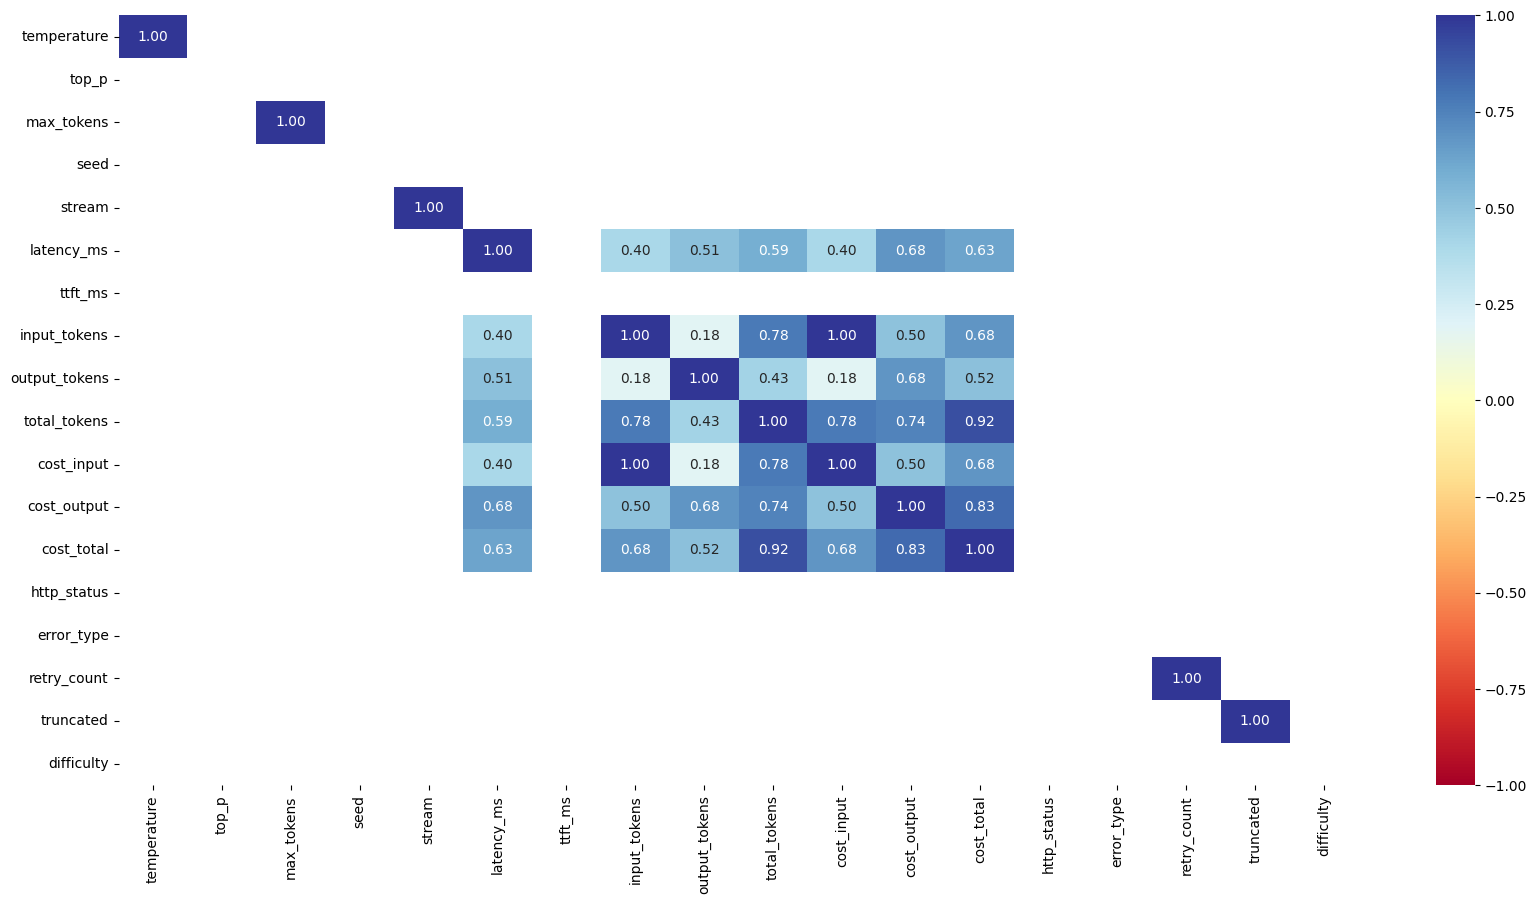

In [24]:
corr_matrix = df.corr(numeric_only=True, method="kendall")

plt.figure(figsize=(20, 10))
sns.heatmap(corr_matrix, vmin=-1, vmax=1, annot=True, fmt=".2f", cmap="RdYlBu", cbar=True)
plt.show()

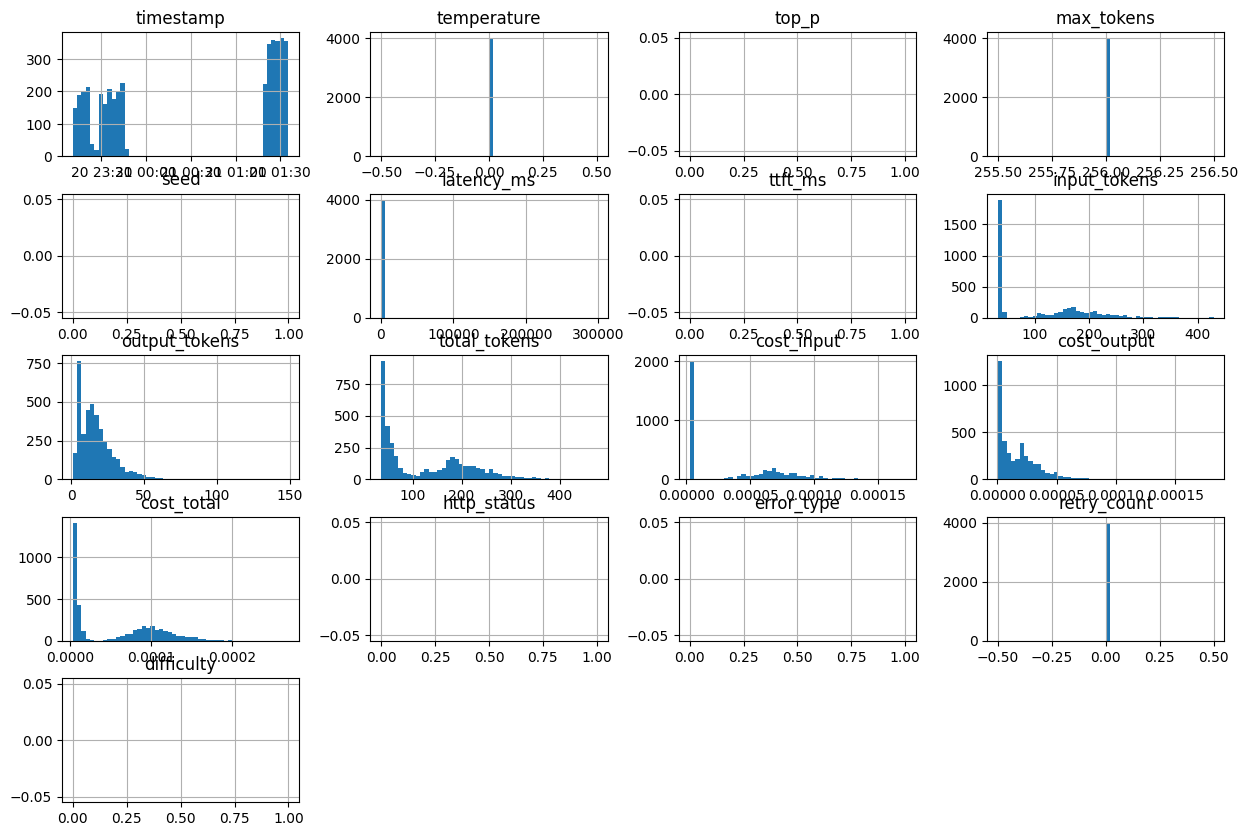

In [8]:
g = df.hist(bins = 50, figsize = (15, 10))

AHP/GS Stage

In [7]:
# Agrupar por modelo e somar apenas colunas numéricas
df_grouped = df.groupby('model', as_index=True).sum(numeric_only=True)

# Seleciona as colunas relevantes para análise
valores_norm = ['input_tokens', 'output_tokens', 'cost_input', 'cost_output']

# Função para calcular fator gaussiano normalizado (retorna também médias e desvios para debug)
def calcular_fator_gaussiano_normalizado(df, columns):
    media = df[columns].mean()
    desvio_padrao = df[columns].std()
    fator_gaussiano = desvio_padrao / media
    fator_normalizado = fator_gaussiano / fator_gaussiano.max()
    return media, desvio_padrao, fator_gaussiano, fator_normalizado

# Calcula o fator
media, desvio_padrao, fator_gaussiano, fator_gaussiano_normalizado = calcular_fator_gaussiano_normalizado(df_grouped, valores_norm)

print("✅ Normalized Gaussian Factor (weights) for selected columns:")
print("\nMean values:")
print(media)
print("\nStandard deviation:")
print(desvio_padrao)
print("\nGaussian factor (std/mean):")
print(fator_gaussiano)
print("\nNormalized Gaussian factor:")
print(fator_gaussiano_normalizado)




✅ Normalized Gaussian Factor (weights) for selected columns:

Mean values:
input_tokens     222738.500000
output_tokens     34150.500000
cost_input            0.077344
cost_output           0.035208
dtype: float64

Standard deviation:
input_tokens     212730.953800
output_tokens      6015.357388
cost_input            0.101711
cost_output           0.037107
dtype: float64

Gaussian factor (std/mean):
input_tokens     0.955070
output_tokens    0.176143
cost_input       1.315044
cost_output      1.053946
dtype: float64

Normalized Gaussian factor:
input_tokens     0.726265
output_tokens    0.133944
cost_input       1.000000
cost_output      0.801453
dtype: float64


DEA Stage

Defining inputs and outputs

In [11]:
# Agrupa apenas colunas numéricas por modelo
df_grouped = df.groupby('model').sum(numeric_only=True)

# Define colunas de input e output
input_cols = ['input_tokens', 'cost_input']
output_cols = ['output_tokens', 'cost_output']
valores_norm = input_cols + output_cols

# Função para coletar monotonicidade (interativa)
def get_monotonicity(valores_norm):
    monotonicity = []
    print("\n🔧 Defina a monotonicidade para cada critério ('max' ou 'min'):")
    for criterion in valores_norm:
        while True:
            resp = input(f"Monotonicidade para '{criterion}': ").strip().lower()
            if resp in ['max', 'min']:
                monotonicity.append(resp)
                break
            else:
                print("Entrada inválida. Digite 'max' ou 'min'.")
    return monotonicity

# Coletar monotonicidade interativamente
monotonicity = get_monotonicity(valores_norm)

# Normalização baseada em monotonicidade
df_normalized = pd.DataFrame(index=df_grouped.index)

for idx, col in enumerate(valores_norm):
    if monotonicity[idx] == 'max':
        df_normalized[col] = df_grouped[col] / df_grouped[col].max()
    else:  # 'min'
        # Adiciona um pequeno epsilon para evitar divisão por zero
        df_normalized[col] = df_grouped[col].min() / (df_grouped[col] + 1e-8)

# Separar inputs e outputs normalizados
inputs_normalized = df_normalized[input_cols]
outputs_normalized = df_normalized[output_cols]

# Mostrar os resultados
print("\n Inputs normalizados:")
print(inputs_normalized)

print("\n Outputs normalizados:")
print(outputs_normalized)

# Se quiser usar os valores normalizados como pesos diretamente (pouco comum, mas didático)
input_weights = inputs_normalized
output_weights = outputs_normalized

print("\n Input Weights (baseados nos valores normalizados):")
print(input_weights)

print("\n Output Weights (baseados nos valores normalizados):")
print(output_weights)



🔧 Defina a monotonicidade para cada critério ('max' ou 'min'):

 Inputs normalizados:
                  input_tokens  cost_input
model                                     
gemini-1.5-flash       0.19379    0.999998
gpt-4.1-mini           1.00000    0.036336

 Outputs normalizados:
                  output_tokens  cost_output
model                                       
gemini-1.5-flash       0.778487     0.999999
gpt-4.1-mini           1.000000     0.145966

 Input Weights (baseados nos valores normalizados):
                  input_tokens  cost_input
model                                     
gemini-1.5-flash       0.19379    0.999998
gpt-4.1-mini           1.00000    0.036336

 Output Weights (baseados nos valores normalizados):
                  output_tokens  cost_output
model                                       
gemini-1.5-flash       0.778487     0.999999
gpt-4.1-mini           1.000000     0.145966


Weighting inputs and outputs

In [12]:
# Aplicar os pesos nos inputs e outputs normalizados
inputs_weighted = inputs_normalized * input_weights
outputs_weighted = outputs_normalized * output_weights

print("\nInputs weighted:")
print(inputs_weighted)
print("\nOutputs weighted:")
print(outputs_weighted)


Inputs weighted:
                  input_tokens  cost_input
model                                     
gemini-1.5-flash      0.037554    0.999996
gpt-4.1-mini          1.000000    0.001320

Outputs weighted:
                  output_tokens  cost_output
model                                       
gemini-1.5-flash       0.606041     0.999998
gpt-4.1-mini           1.000000     0.021306


In [13]:
# Confirma que inputs_weighted e outputs_weighted existem (podem ser os próprios inputs/outputs normalizados)
# Exemplo: 
# inputs_weighted = inputs_normalized
# outputs_weighted = outputs_normalized

n_dmus = df_grouped.shape[0]  # Número de DMUs
dmu_names = df_grouped.index   # Nome dos DMUs (model)

# Calcular soma ponderada de inputs e outputs
weighted_sum_inputs = inputs_weighted.sum(axis=1).values
weighted_sum_outputs = outputs_weighted.sum(axis=1).values

# Calcular eficiência
efficiency_scores = weighted_sum_outputs / weighted_sum_inputs

# Criar DataFrame de resultados
df_results = pd.DataFrame({
    'Criteria': dmu_names,               # DMU names
    'Weighted Inputs': weighted_sum_inputs,
    'Weighted Outputs': weighted_sum_outputs,
    'Efficiency': efficiency_scores
})

# Normalizar para eficiência relativa
max_efficiency = df_results['Efficiency'].max()
df_results['Relative Efficiency'] = df_results['Efficiency'] / max_efficiency

# Ordenar por eficiência e criar ranking
df_results = df_results.sort_values(by='Efficiency', ascending=False)
df_results['Ranking'] = df_results['Efficiency'].rank(ascending=False, method='min').astype(int)

# Reordenar colunas
df_results = df_results[['Criteria', 'Weighted Inputs', 'Weighted Outputs', 'Efficiency', 'Relative Efficiency', 'Ranking']]

# Resetar índice e exibir
df_results = df_results.reset_index(drop=True)
df_results


,Criteria,Weighted Inputs,Weighted Outputs,Efficiency,Relative Efficiency,Ranking
0,gemini-1.5-flash,1.037551,1.606039,1.547914,1.000000,1
1,gpt-4.1-mini,1.001320,1.021306,1.019960,0.658925,2


Plotagem do gráfico (a refinar)

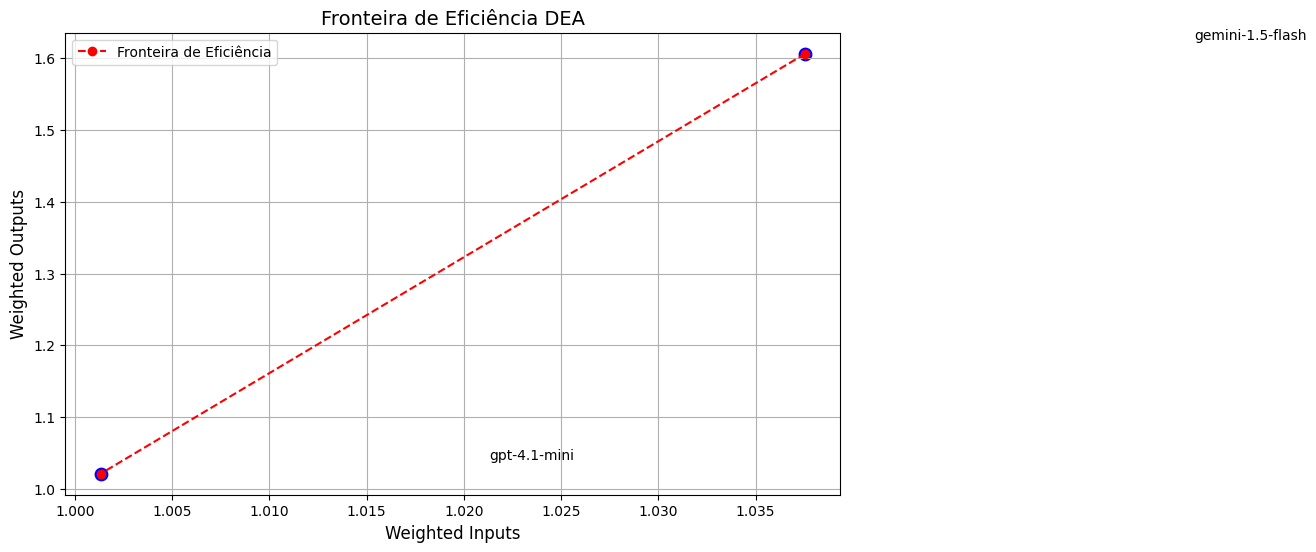

In [14]:
# Ordem manual da fronteira
ordem_fronteira = ["gemini-1.5-flash", "gpt-4.1-mini"]
df_fronteira = df_results.set_index("Criteria").loc[ordem_fronteira].reset_index()

# Plot dos pontos
plt.figure(figsize=(10, 6))
plt.scatter(df_results["Weighted Inputs"], df_results["Weighted Outputs"], color="blue", s=80)

# Adiciona os labels (Criteria)
for i, row in df_results.iterrows():
    plt.text(row["Weighted Inputs"] + 0.02, row["Weighted Outputs"] + 0.02, 
             row["Criteria"], fontsize=10)

# Linha pontilhada da fronteira DEA (D → C → A) com legenda
plt.plot(df_fronteira["Weighted Inputs"], df_fronteira["Weighted Outputs"], 
         linestyle="--", color="red", marker="o", label="Fronteira de Eficiência")

# Labels e título
plt.xlabel("Weighted Inputs", fontsize=12)
plt.ylabel("Weighted Outputs", fontsize=12)
plt.title("Fronteira de Eficiência DEA", fontsize=14)
plt.grid(True)
plt.legend()
plt.show()
